In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

Loading Data Set

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Data Cleaning

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [8]:
df = df.drop("customerID", axis=1)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

In [9]:
df.duplicated().sum()

np.int64(22)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


Outlier Detection

In [11]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2281.916928
std,0.368612,24.559481,30.090047,2265.270398
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,402.225000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


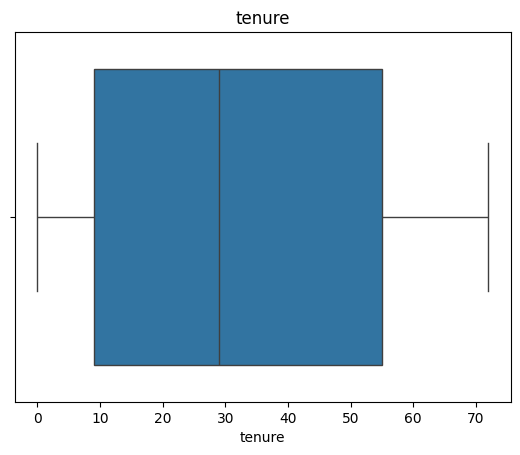

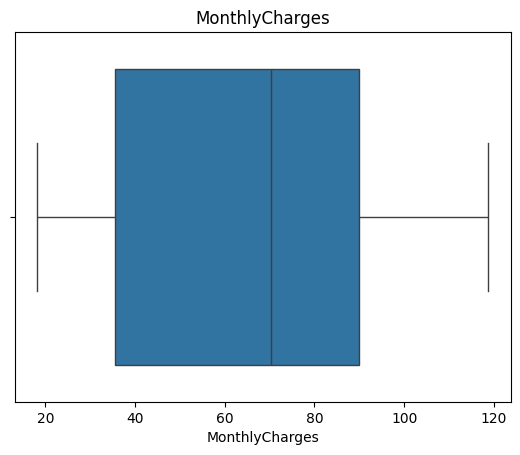

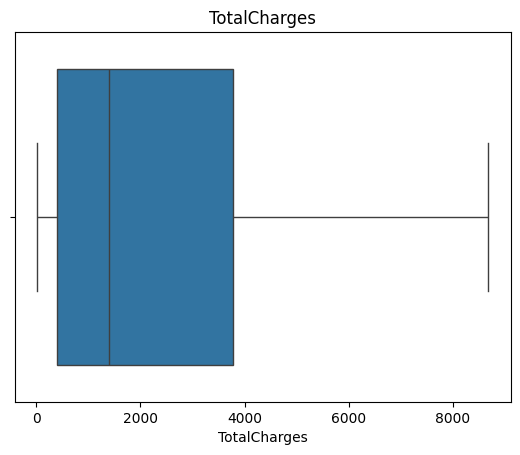

In [12]:
columns = ["tenure", "MonthlyCharges", "TotalCharges"]

for col in columns:
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

In [13]:
for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, ":", len(outliers), "outliers")

tenure : 0 outliers
MonthlyCharges : 0 outliers
TotalCharges : 0 outliers


Encoding

In [14]:
from sklearn.preprocessing import LabelEncoder

df.select_dtypes(include="object").columns

le = LabelEncoder()

for col in df.select_dtypes(include="object").columns:
    df[col] = le.fit_transform(df[col])

In [15]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


Split the Dataset

In [16]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

In [17]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Baseline Decision Tree Model with 5-Fold Cross-Validation

In [20]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [21]:
cv_scores = cross_val_score(dt, X_train, y_train, cv=5, scoring="accuracy")

print("CV Scores:", cv_scores)
print("Mean CV Accuracy:", cv_scores.mean())

CV Scores: [0.73469388 0.74001775 0.75066548 0.7364685  0.72468917]
Mean CV Accuracy: 0.7373069545989683


In [22]:
y_pred = dt.predict(X_test)

In [23]:
baseline_accuracy = accuracy_score(y_test, y_pred)

print("Baseline Test Accuracy:", baseline_accuracy)

Baseline Test Accuracy: 0.730305180979418


In [24]:
print("Training Accuracy:", dt.score(X_train, y_train))
print("Testing Accuracy:", dt.score(X_test, y_test))

Training Accuracy: 0.9980475683351083
Testing Accuracy: 0.730305180979418


Hyperparameter Tuning using GridSearchCV

In [25]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "max_depth": [3, 5, 10],
    "min_samples_split": [2, 5, 10],
    "criterion": ["gini", "entropy"]
}

In [26]:
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="accuracy"
)

grid.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [3, 5, 10],
                         'min_samples_split': [2, 5, 10]},
             scoring='accuracy')

In [27]:
print("Best Parameters:", grid.best_params_)
print("Best CV Accuracy:", grid.best_score_)

Best Parameters: {'criterion': 'gini', 'max_depth': 5, 'min_samples_split': 2}
Best CV Accuracy: 0.7912630555349794


In [28]:
y_pred_grid = grid.predict(X_test)

In [29]:
grid_accuracy = accuracy_score(y_test, y_pred_grid)

print("GridSearchCV Test Accuracy:", grid_accuracy)

GridSearchCV Test Accuracy: 0.7849538679914834


In [30]:
print("Baseline Accuracy:", baseline_accuracy)
print("GridSearchCV Accuracy:", grid_accuracy)

Baseline Accuracy: 0.730305180979418
GridSearchCV Accuracy: 0.7849538679914834


Hyperparameter Tuning — RandomizedSearchCV

In [31]:
from sklearn.model_selection import RandomizedSearchCV

param_random = {
    "max_depth": [3, 5, 10],
    "min_samples_split": [2, 5, 10],
    "criterion": ["gini", "entropy"]
}

In [32]:
random = RandomizedSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_random,
    n_iter=10,
    cv=5,
    scoring="accuracy",
    random_state=42
)

In [33]:
random.fit(X_train, y_train)

RandomizedSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42),
                   param_distributions={'criterion': ['gini', 'entropy'],
                                        'max_depth': [3, 5, 10],
                                        'min_samples_split': [2, 5, 10]},
                   random_state=42, scoring='accuracy')

In [34]:
print("Best Parameters:", random.best_params_)
print("Best CV Accuracy:", random.best_score_)

Best Parameters: {'min_samples_split': 2, 'max_depth': 5, 'criterion': 'gini'}
Best CV Accuracy: 0.7912630555349794


In [35]:
y_pred_random = random.predict(X_test)

In [36]:
random_accuracy = accuracy_score(y_test, y_pred_random)

print("RandomizedSearchCV Test Accuracy:", random_accuracy)

RandomizedSearchCV Test Accuracy: 0.7849538679914834


In [37]:
print("Baseline Accuracy:", baseline_accuracy)
print("GridSearchCV Accuracy:", grid_accuracy)
print("RandomizedSearchCV Accuracy:", random_accuracy)

Baseline Accuracy: 0.730305180979418
GridSearchCV Accuracy: 0.7849538679914834
RandomizedSearchCV Accuracy: 0.7849538679914834


Ensemble Learning — Random Forest Classifier

In [38]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
rf_cv = cross_val_score(rf, X_train, y_train, cv=5, scoring="accuracy")

print("CV Scores:", rf_cv)
print("Mean CV Accuracy:", rf_cv.mean())

CV Scores: [0.7985803  0.79946761 0.78438332 0.7755102  0.77797513]
Mean CV Accuracy: 0.7871833141318926


In [39]:
y_pred_rf = rf.predict(X_test)

In [40]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Test Accuracy:", rf_accuracy)

Random Forest Test Accuracy: 0.7920511000709723


In [41]:
print("Training Accuracy:", rf.score(X_train, y_train))
print("Testing Accuracy:", rf.score(X_test, y_test))

Training Accuracy: 0.9980475683351083
Testing Accuracy: 0.7920511000709723


In [42]:
print("Decision Tree:", baseline_accuracy)
print("GridSearchCV:", grid_accuracy)
print("RandomizedSearchCV:", random_accuracy)
print("Random Forest:", rf_accuracy)

Decision Tree: 0.730305180979418
GridSearchCV: 0.7849538679914834
RandomizedSearchCV: 0.7849538679914834
Random Forest: 0.7920511000709723


Final Model Comparison Table

In [43]:
results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "GridSearchCV",
        "RandomizedSearchCV",
        "Random Forest"
    ],
    "CV Accuracy": [
        cv_scores.mean(),
        grid.best_score_,
        random.best_score_,
        rf_cv.mean()
    ],
    "Test Accuracy": [
        baseline_accuracy,
        grid_accuracy,
        random_accuracy,
        rf_accuracy
    ],
    "Best Parameters": [
        "Default",
        str(grid.best_params_),
        str(random.best_params_),
        "n_estimators=100"
    ]
})

results

,Model,CV Accuracy,Test Accuracy,Best Parameters
0,Decision Tree,0.737307,0.730305,Default
1,GridSearchCV,0.791263,0.784954,"{'criterion': 'gini', 'max_depth': 5, 'min_sam..."
2,RandomizedSearchCV,0.791263,0.784954,"{'min_samples_split': 2, 'max_depth': 5, 'crit..."
3,Random Forest,0.787183,0.792051,n_estimators=100


In [44]:
best_model = results.loc[results["CV Accuracy"].idxmax()]

print("Best Model:", best_model["Model"])
print("CV Accuracy:", best_model["CV Accuracy"])
print("Test Accuracy:", best_model["Test Accuracy"])

Best Model: GridSearchCV
CV Accuracy: 0.7912630555349794
Test Accuracy: 0.7849538679914834


### Conclusion

In this assignment, I used the Telco Customer Churn dataset to predict customer churn. I trained a Decision Tree model, optimized it using GridSearchCV and RandomizedSearchCV, and implemented Random Forest. Finally, I compared the models using cross-validation and test accuracy. This helped me understand model tuning and ensemble learning.